In [ ]:
"""
<앙상블 모델>
 - 결정트리(DT)를 기반으로 만들어진 모델
 - 여러개의 트리 모델을 이용하여 훈련하는 모델을 앙상블 모델이라고 칭합니다.
 - 여러개의 트리 모델들이 모여있다고 해서 앙상블 이라고 칭합니다.
 - 교차검증 수행방식을 포함하고 있는 모델임

<앙상블 모델 분류>
 * 회귀와 분류에서 모두 사용가능한 모델
  - sklearn 패키지 모델은 모두 가능
  - 랜덤포레스트, 엑스트라트리, 
  - 그레디언트 부스팅, 히스토그램 그레디언트 부스팅
  - XGBooting, LightBGM, 등등

  --------------------------------------------------------------------
  
<배깅(Bagging)과 부스팅(Boosting) 방식>
 - 훈련데이터를 여러 모델에 적용하는 방식에 따라 배깅과 부스팅 방식으로 구분함

<배깅>
 - 사용되는 여러개의 모델은 서로간에 독립적으로 사용됨(연관성 없음)
 - 훈련데이터는 여러 모델에 랜덤하게 적용되며, 중복되는 데이터가 있을 수도 있음
 - ***훈련데이터를 사용 후 반환하는 방식 > 반환 후 다시 랜덤하게 추출하여 사용됨
 - 대표적인 앙상블 모델은 랜덤포레스트 모델이 있음
 - 모델 : 램덤포레스트, 엑스트라트리
 - 예측 : 회귀에서는 평균값을, 분류에서는 과반수에 따라 확률로 경정됨
 ** 과적합을 해소하는 모델로 주로 사용됨
 
<부스팅>
 - 사용되는 여러개의 모델은 연관성을 가짐
 - 사용된 이전모델의 오차를 보완하는 방식으로 사용됨
 - 데이터는 랜덤하게 추출되어 사용되지만,
   이전 모델훈련에서 오차가 크게 발생했던 훈련데이터에 가중치를 부여하는 방식으로
   데이터가 모델에 적용됨
 - 대표적인 앙상블 모델은 그레디언트 부스팅 모델이 있음
 - 모델 : 그레디언트 부스팅, 히스토그램 그레디언트 부스팅
 ** 정확도를 높이는 모델로 주로 사용됨
 
<실제 모델 적용시>
 - 앙상블 모델이 아닌 단일모델(결정트리)을 우선 사용
 - 과적합 또는 정확도 문제 발생 시 배깅 또는 부스팅 방식으로 확대 적용
 - 앙상블 모델은 랜덤포레스트를 처음 적용하는 것이 일반적임
 - 최종 모델 선정 시에는 모든 앙상블 모델을 훈련시킨 후 과적합/정확도/재현율/F1-Score 등을 고려하여
   선정하게 됨
"""

### 라이브러리 불러들이기

In [ ]:
%run ../common/libraries.py

# 이번 학습에서 사용하는 주요 라이브러리
# - pandas(pd) : CSV 및 DataFrame 데이터 처리
# - matplotlib(plt) : 그래프 시각화
# - train_test_split : 훈련/검증/테스트 데이터 분리
# - StandardScaler : 표준화 스케일링
# - RandomForestClassifier : 랜덤포레스트 분류 모델
# - ExtraTreesClassifier : 엑스트라트리 분류 모델
# - GradientBoostingClassifier : 그래디언트 부스팅 분류 모델
# - HistGradientBoostingClassifier : 히스토그램 그래디언트 부스팅 분류 모델
# - XGBClassifier : XGBoost 분류 모델
# - confusion_matrix : 오차행렬 생성
# - ConfusionMatrixDisplay : 오차행렬 시각화
# - accuracy_score : 정확도 평가
# - precision_score : 정밀도 평가
# - recall_score : 재현율 평가
# - f1_score : F1-Score 평가


### 데이터 불러들이기

In [2]:
### 사용할 데이터셋 : data 폴더 안에 csv 파일 사용
# - 변수명 : wine
# - 데이터셋 정보확인
file_path = "../data/08_wine.csv"
wine = pd.read_csv(file_path)

wine.info()
display(wine.describe())
wine.head(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0


### 독립변수와 종속변수로 분리하기

In [5]:
### 독립변수명 : data, 종속변수명 : target
# - 독립변수와 종속변수 데이터 타입은 리스트 타입으로(numpy의 array) 변환해서 저장하기
data = wine.iloc[:, :-1].to_numpy()
target = wine["class"].to_numpy()

print(data.shape, target.shape)
data, target

(6497, 3) (6497,)


(array([[ 9.4 ,  1.9 ,  3.51],
        [ 9.8 ,  2.6 ,  3.2 ],
        [ 9.8 ,  2.3 ,  3.26],
        ...,
        [ 9.4 ,  1.2 ,  2.99],
        [12.8 ,  1.1 ,  3.34],
        [11.8 ,  0.8 ,  3.26]], shape=(6497, 3)),
 array([0., 0., 0., ..., 1., 1., 1.], shape=(6497,)))

### 훈련:테스트 = 8:2로 분리

In [6]:
### 변수명 : train_input, train_target, test_input, test_target
train_input, test_input, train_target, test_target = train_test_split(
    data, target, test_size=0.2, stratify=target, random_state=42
)

print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)

(5197, 3) (5197,)
(1300, 3) (1300,)


### 데이터 스케일링(표준화) 시키기

In [ ]:
"""
<데이터 스케일링>
 - 서로다른 변수의 값의 단위를 일정한 수준으로 맞추는 작업을 스케일링 이라고 칭함
 - 데이터 스케일링을 현업에서는 정규화 또는 표준화라고 소통하고 있음
 - 스케일링 방법 3가지
   -> StandardScaler(표준화), RobustScaler, MinMaxScaler


<주 사용처>
 - StandardScaler : 주로 분류에서 사용되며, 회귀에서도 사용은 가능(가장 많이 사용됨)(-4~4)
 - RobustScaler   : 분류 및 회귀에서 모두 사용 가능
 - MinMaxScaler   : 주로 회귀에서 사용되며, 분류에서도 사용은 가능(0~1)
 - 회귀 또는 분류분석 시 훈련 방법(회귀/분류)에 따라 선택 사용하면 됨
"""

In [8]:
### 변수명 : train_scaled, test_scaled
ss = StandardScaler()
ss.fit(train_input)

train_scaled = ss.transform(train_input)
test_scaled  = ss.transform(test_input)

print(train_scaled.shape, train_target.shape)
print(test_scaled.shape, test_target.shape)
train_scaled

(5197, 3) (5197,)
(1300, 3) (1300,)


array([[-0.91211058,  1.22911099, -0.17470179],
       [ 0.42727963, -0.88716382, -0.98652017],
       [ 0.59470341, -0.12530489, -0.61183476],
       ...,
       [-1.24695813,  1.96980717, -1.61099585],
       [ 1.85038173,  0.78469328, -0.36204449],
       [-0.99582247,  0.36143832, -0.86162503]], shape=(5197, 3))

### 랜덤포래스트 모델로 훈련시키기

In [9]:
### 과적합 여부 확인까지만 진행...
rf = RandomForestClassifier(random_state=42)
rf.fit(train_scaled, train_target)

train_score = rf.score(train_scaled, train_target)
test_score  = rf.score(test_scaled, test_target)

print(train_score, test_score, train_score - test_score)

0.9978833942659227 0.8907692307692308 0.1071141634966919


### 임의의 값으로 예측하기

In [11]:
### 스케일링된 테스트 데이터의 0번째 행부터 10개 행만 추출하여 예측하기
temp_pred = rf.predict(test_scaled[:10])
print(temp_pred)

### 실제 정답 10개
print(test_target[:10])

[0. 1. 1. 1. 1. 0. 0. 1. 1. 1.]
[1. 1. 1. 1. 1. 0. 0. 1. 1. 1.]


### 임의 10개 예측결과를 이용하여 성능평가해 보기

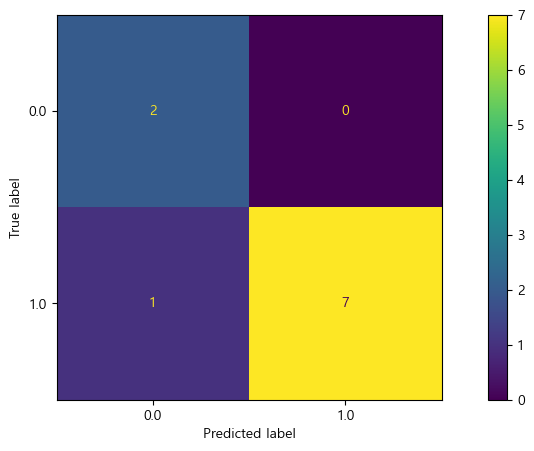

0.90000000, 1.00000000, 0.87500000, 0.93333333


In [12]:
### 오차행렬표, 오차행렬도, 정확도, 정밀도, 재현율, f1-score 확인하기
# 오차행렬표
cm = confusion_matrix(test_target[:10], temp_pred, labels=rf.classes_)

# 오차행렬도
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf.classes_)
disp.plot()
plt.show()

# 평가(정확도, 정밀도, 재현율, f1-score)
temp_acc = accuracy_score(test_target[:10], temp_pred)
temp_pre = precision_score(test_target[:10], temp_pred)
temp_rec = recall_score(test_target[:10], temp_pred)
temp_f1  = f1_score(test_target[:10], temp_pred)

print(f"{temp_acc:.8f}, {temp_pre:.8f}, {temp_rec:.8f}, {temp_f1:.8f}")


### 훈련 및 테스트 데이터 전체로 성능평가하기

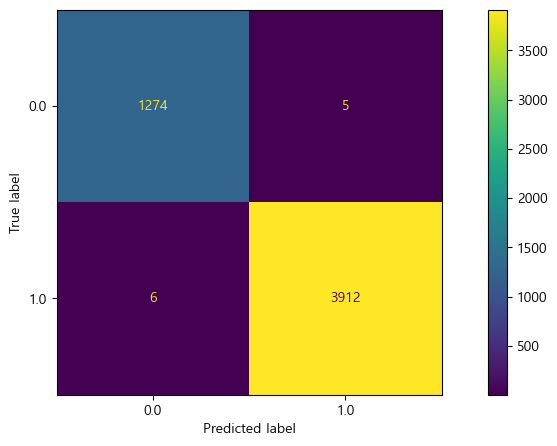

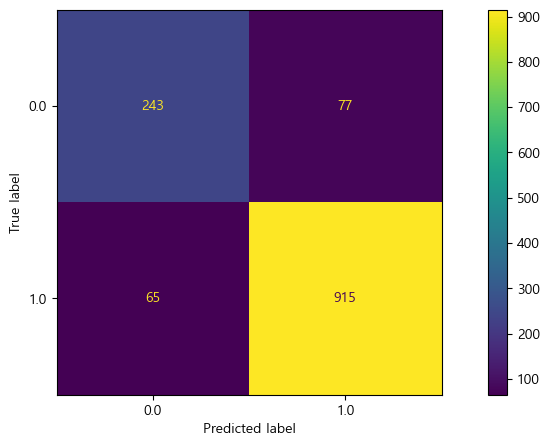

[훈련] : 0.99788, 0.99872, 0.99847, 0.99860
[테스트] : 0.89077, 0.92238, 0.93367, 0.92799
과적합여부 : 0.10711


In [15]:
### 예측, 오차행렬표, 오차행렬도, 정확도, 정밀도, 재현율, f1-score 확인하기
train_pred = rf.predict(train_scaled)
test_pred  = rf.predict(test_scaled)

train_cm = confusion_matrix(train_target, train_pred)
test_cm  = confusion_matrix(test_target, test_pred)

train_disp = ConfusionMatrixDisplay(confusion_matrix=train_cm, display_labels=rf.classes_)
test_disp  = ConfusionMatrixDisplay(confusion_matrix=test_cm, display_labels=rf.classes_)

train_disp.plot()
plt.show()

test_disp.plot()
plt.show()

train_acc = accuracy_score(train_target, train_pred)
test_acc = accuracy_score(test_target, test_pred)

train_pre = precision_score(train_target, train_pred)
test_pre = precision_score(test_target, test_pred)

train_rec = recall_score(train_target, train_pred)
test_rec = recall_score(test_target, test_pred)

train_f1 = f1_score(train_target, train_pred)
test_f1 = f1_score(test_target, test_pred)

print(f"[훈련] : {train_acc:.5f}, {train_pre:.5f}, {train_rec:.5f}, {train_f1:.5f}")
print(f"[테스트] : {test_acc:.5f}, {test_pre:.5f}, {test_rec:.5f}, {test_f1:.5f}")
print(f"과적합여부 : {train_acc - test_acc:.5f}")

### 과대적합 발생 -> 하이퍼파라메터 튜닝 해보기 -> 다른 모델 사용해보기

In [21]:
### 랜덤포레스트 모델 사용....
# - 트리 갯수 조정하여 튜닝하기
# - 트리 갯수 하이퍼파라메터 변수명 : n_estimators : 기본값은 100
# - 트리의 갯수 10~100까지 적용하여 랜덤포레스트 과적합까지만 확인해보기
# - CPU core는 전체 사용(-1사용), 랜덤규칙 42 사용

model = RandomForestClassifier(random_state=42, n_jobs=-1)

for n in range(10, 101, 1) :
    model.n_estimators = n
    model.fit(train_scaled, train_target)

    train_score = model.score(train_scaled, train_target)
    test_score = model.score(test_scaled, test_target)

    print(f"[{n}] : {train_score:.5f}, {test_score:.5f}, {train_score - test_score:.5f}")

[10] : 0.99096, 0.88615, 0.10480
[11] : 0.99057, 0.88923, 0.10134
[12] : 0.99327, 0.88538, 0.10788
[13] : 0.99327, 0.88692, 0.10634
[14] : 0.99288, 0.88154, 0.11134
[15] : 0.99250, 0.88692, 0.10557
[16] : 0.99384, 0.88615, 0.10769
[17] : 0.99346, 0.88846, 0.10500
[18] : 0.99423, 0.88385, 0.11038
[19] : 0.99365, 0.88308, 0.11057
[20] : 0.99423, 0.88385, 0.11038
[21] : 0.99500, 0.88154, 0.11346
[22] : 0.99538, 0.88308, 0.11231
[23] : 0.99519, 0.88000, 0.11519
[24] : 0.99557, 0.88231, 0.11327
[25] : 0.99577, 0.88308, 0.11269
[26] : 0.99596, 0.88462, 0.11134
[27] : 0.99615, 0.88923, 0.10692
[28] : 0.99654, 0.88846, 0.10807
[29] : 0.99654, 0.89077, 0.10577
[30] : 0.99654, 0.88692, 0.10961
[31] : 0.99673, 0.88923, 0.10750
[32] : 0.99711, 0.88615, 0.11096
[33] : 0.99711, 0.88538, 0.11173
[34] : 0.99711, 0.88538, 0.11173
[35] : 0.99750, 0.88692, 0.11058
[36] : 0.99731, 0.88538, 0.11192
[37] : 0.99731, 0.88769, 0.10961
[38] : 0.99750, 0.88923, 0.10827
[39] : 0.99750, 0.88923, 0.10827
[40] : 0.9

### 5개 앙상블 모델을 모두 사용하여 과적합 여부까지만 확인해보기

In [29]:
### 트리갯수 10~100까지 사용(반복)..
# - 일반화 가능한 모델이 있는지 확인해 주세요..
rf  = RandomForestClassifier(random_state=42, n_jobs=-1)
et  = ExtraTreesClassifier(random_state=42, n_jobs=-1)
gb  = GradientBoostingClassifier(random_state=42)
rgb = HistGradientBoostingClassifier(random_state=42)
xgb = XGBClassifier(random_state=42, n_jobs=-1)

model_list = [rf, et, gb, rgb, xgb]

for model in model_list :
    model_name = model.__class__.__name__
    print(f"=========== [{model_name}] ============")

    for n in range(10, 101, 1) :        
        model.n_estimators = n
        model.fit(train_scaled, train_target)

        train_score = model.score(train_scaled, train_target)
        test_score = model.score(test_scaled, test_target)
        train_test = train_score - test_score

        if train_score < 1 :
            if train_test < 0.1 :
                print(f"{model_name}[{n}] : {train_score:.5f}, {test_score:.5f}, {train_score - test_score:.5f} \n\n")
                break

print("작업 종료..........")            

=========== [RandomForestClassifier] ============
=========== [ExtraTreesClassifier] ============
=========== [GradientBoostingClassifier] ============
GradientBoostingClassifier[10] : 0.85049, 0.83846, 0.01203 


=========== [HistGradientBoostingClassifier] ============
HistGradientBoostingClassifier[10] : 0.92669, 0.87769, 0.04900 


=========== [XGBClassifier] ============
XGBClassifier[10] : 0.89186, 0.86462, 0.02725 


작업 종료..........


In [ ]:
### 트리갯수 10~100까지 사용(반복)..
# - 일반화 가능한 모델이 있는지 확인해 주세요..
rf  = RandomForestClassifier(random_state=42, n_jobs=-1)
et  = ExtraTreesClassifier(random_state=42, n_jobs=-1)
gb  = GradientBoostingClassifier(random_state=42)
hgb = HistGradientBoostingClassifier(random_state=42)
xgb = XGBClassifier(random_state=42, n_jobs=-1)

# model_list = [rf, et, gb, hgb, xgb]
model_list = [gb, hgb, xgb]

for model in model_list :
    model_name = model.__class__.__name__
    print(f"=========== [{model_name}] ============")

    for n in range(10, 101, 1) :  
        if model_name in ["GradientBoostingClassifier", "XGBClassifier"] :
            model.n_estimators = n
        else :
            model.max_iter = n

        model.fit(train_scaled, train_target)

        train_score = model.score(train_scaled, train_target)
        test_score = model.score(test_scaled, test_target)
        train_test = train_score - test_score

        # if train_score < 1 :
        #     if train_test < 0.1 :
        #         print(f"{model_name}[{n}] : {train_score:.5f}, {test_score:.5f}, {train_score - test_score:.5f} \n\n")
        #         break
        print(f"{model_name}[{n}] : {train_score:.5f}, {test_score:.5f}, {train_score - test_score:.5f}")

print("작업 종료..........")        

### GradientBoostingClassifier[10]     : 0.85049, 0.83846, 0.01203 
### HistGradientBoostingClassifier[10] : 0.88667, 0.85846, 0.02820
### XGBClassifier[14]                  : 0.89282, 0.86846, 0.02436

=========== [GradientBoostingClassifier] ============
GradientBoostingClassifier[10] : 0.85049, 0.83846, 0.01203
GradientBoostingClassifier[11] : 0.85165, 0.83846, 0.01318
GradientBoostingClassifier[12] : 0.86261, 0.84462, 0.01800
GradientBoostingClassifier[13] : 0.86204, 0.84385, 0.01819
GradientBoostingClassifier[14] : 0.86665, 0.84385, 0.02281
GradientBoostingClassifier[15] : 0.86762, 0.84692, 0.02069
GradientBoostingClassifier[16] : 0.86781, 0.84692, 0.02089
GradientBoostingClassifier[17] : 0.86954, 0.84692, 0.02262
GradientBoostingClassifier[18] : 0.86954, 0.84615, 0.02339
GradientBoostingClassifier[19] : 0.87012, 0.84692, 0.02319
GradientBoostingClassifier[20] : 0.87204, 0.84692, 0.02512
GradientBoostingClassifier[21] : 0.87185, 0.84769, 0.02416
GradientBoostingClassifier[22] : 0.87281, 0.84846, 0.02435
GradientBoostingClassifier[23] : 0.87358, 0.84769, 0.02589
GradientBoostingClassifier[24] : 0.87531, 0.84769, 0.02762
GradientBoostingClassifier[25] : 0.87685, 0.84846, 0.02839
Gr

### 일반화가 잘된 모델들에 대해서 예측 및 평가하여 최종 모델 선정하기

In [ ]:
### GradientBoostingClassifier[10]     : 0.85049, 0.83846, 0.01203 
### HistGradientBoostingClassifier[10] : 0.88667, 0.85846, 0.02820
### XGBClassifier[14]                  : 0.89282, 0.86846, 0.02436

In [ ]:
### 훈련 데이터만 사용해서 진행
# - HGB의 트리갯수 : n_estimators 사용은 가능 -> max_iter로 사용
# - GB와 HGB는 n_jobs 속성이 없음
#   -> HGB는 기본적으로 모든 core를 사용
#   -> GB는 기본 1개 core 사용

gb  = GradientBoostingClassifier(random_state=42, n_estimators=10)
hgb = HistGradientBoostingClassifier(random_state=42, max_iter=10)
xgb = XGBClassifier(random_state=42, n_jobs=-1, n_estimators=14)

model_list = [gb, hgb, xgb]

for model in model_list :
    model_name = model.__class__.__name__
    
    model.fit(train_scaled, train_target)

    train_pred = model.predict(train_scaled)

    train_acc = accuracy_score(train_target, train_pred)
    train_pre = precision_score(train_target, train_pred)
    train_rec = recall_score(train_target, train_pred)
    train_f1 = f1_score(train_target, train_pred)

    print(f"[{model_name}] : {train_acc:.5f}, {train_pre:.5f}, {train_rec:.5f}, {train_f1:.5f}")

print("작업 종료..........")   

# [GradientBoostingClassifier]      : 0.85049, 0.85459, 0.96605, 0.90691
# [HistGradientBoostingClassifier]  : 0.88667, 0.89341, 0.96478, 0.92772
# [XGBClassifier]                   : 0.89282, 0.92620, 0.93211, 0.92914

### 정확도, 정밀도, f1-score가 가장 높고, 재현율도 매우 좋은 편으로 XGB 모델 선정이 타당함

[GradientBoostingClassifier] : 0.85049, 0.85459, 0.96605, 0.90691
[HistGradientBoostingClassifier] : 0.88667, 0.89341, 0.96478, 0.92772
[XGBClassifier] : 0.89282, 0.92620, 0.93211, 0.92914
작업 종료..........
